**Anuska Nath**

**IT-UG-4**

**Assignment - 3**

---
# PART 1 : Hidden Markov Model (HMM) Classification

 — HMM classification (GaussianHMM & MultinomialHMM) on the
Ionosphere and Wisconsin Breast Cancer datasets.
---


**🔹Install dependencies**

In [ ]:
# Cell 1: Install dependencies
%pip install -q hmmlearn ucimlrepo
print("Installation  finished.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 2.2 MB/s eta 0:00:00
Installation  finished.


**🔹Imports**

In [ ]:
# Cell 2: Imports
# Safety net: re-installs hmmlearn here too, in case Cell 1 was skipped or run
# in a different kernel session than this one.
try:
    import hmmlearn  # noqa: F401
except ModuleNotFoundError:
    %pip install -q hmmlearn
    import hmmlearn  # noqa: F401

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import product

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, KBinsDiscretizer
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, roc_curve, auc)
from sklearn.datasets import load_breast_cancer

from hmmlearn.hmm import GaussianHMM, MultinomialHMM

np.random.seed(42)
sns.set_style("whitegrid")


**🔹 Load datasets**

In [ ]:
# Cell 3: Load datasets
# ---- (a) Wisconsin Breast Cancer Diagnostic (built into sklearn, matches UCI dataset) ----
bc = load_breast_cancer()
X_bc = bc.data.astype(float)
y_bc = bc.target.astype(int)  # 0 = malignant, 1 = benign

# ---- (b) Ionosphere (fetched directly from UCI repository) ----
ionosphere_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/ionosphere/ionosphere.data"
iono_df = pd.read_csv(ionosphere_url, header=None)
X_iono = iono_df.iloc[:, :-1].values.astype(float)
y_iono_raw = iono_df.iloc[:, -1].values
le = LabelEncoder()
y_iono = le.fit_transform(y_iono_raw)  # 'g'/'b' -> 1/0

datasets = {
    "Ionosphere": (X_iono, y_iono),
    "BreastCancer": (X_bc, y_bc),
}

for name, (X, y) in datasets.items():
    print(name, "X:", X.shape, "y:", y.shape, "classes:", np.unique(y, return_counts=True))


Ionosphere X: (351, 34) y: (351,) classes: (array([0, 1]), array([126, 225]))
BreastCancer X: (569, 30) y: (569,) classes: (array([0, 1]), array([212, 357]))


**🔹Helper — treat each feature vector as a short sequence**

In [ ]:
# Cell 4: Helper — treat each feature vector as a short sequence
# HMMs need sequences. We reshape each sample's F features into a length-F
# sequence with 1 observation dimension. One HMM is trained PER CLASS; a test
# sample is scored against every class-HMM and assigned to the class with the
# highest log-likelihood.

def to_sequences(X):
    """(n_samples, n_features) -> list of (n_features, 1) sequences + lengths array"""
    seqs = [x.reshape(-1, 1) for x in X]
    lengths = [s.shape[0] for s in seqs]
    return seqs, lengths

def stack_sequences(seqs):
    return np.vstack(seqs)


**🔹Train / predict / score routines for class-wise HMMs**

In [ ]:
# Cell 5: Train / predict / score routines for class-wise HMMs

def train_classwise_gaussian_hmm(X_train, y_train, n_components=2, covariance_type="diag",
                                  n_iter=100, random_state=42):
    models = {}
    for c in np.unique(y_train):
        Xc = X_train[y_train == c]
        seqs, lengths = to_sequences(Xc)
        model = GaussianHMM(n_components=n_components, covariance_type=covariance_type,
                             n_iter=n_iter, random_state=random_state, tol=1e-3)
        model.fit(stack_sequences(seqs), lengths)
        models[c] = model
    return models

def train_classwise_multinomial_hmm(X_train_disc, y_train, n_components=2,
                                     n_iter=100, random_state=42):
    models = {}
    for c in np.unique(y_train):
        Xc = X_train_disc[y_train == c]
        seqs, lengths = to_sequences(Xc)
        model = MultinomialHMM(n_components=n_components, n_iter=n_iter,
                                random_state=random_state, tol=1e-3)
        model.fit(stack_sequences(seqs).astype(int), lengths)
        models[c] = model
    return models

def classwise_loglik_matrix(models, X):
    """Return (n_samples, n_classes) matrix of log-likelihoods, and class order."""
    classes = sorted(models.keys())
    seqs, _ = to_sequences(X)
    L = np.zeros((len(seqs), len(classes)))
    for j, c in enumerate(classes):
        for i, s in enumerate(seqs):
            try:
                L[i, j] = models[c].score(s)
            except Exception:
                L[i, j] = -np.inf
    return L, classes

def predict_from_loglik(L, classes):
    idx = np.argmax(L, axis=1)
    return np.array([classes[i] for i in idx])

def loglik_to_proba(L):
    """Softmax over class log-likelihoods -> pseudo-probabilities, for ROC/AUC."""
    L = L - L.max(axis=1, keepdims=True)
    E = np.exp(L)
    return E / E.sum(axis=1, keepdims=True)


**🔹Metrics helper**

In [ ]:
# Cell 6: Metrics helper

def compute_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average="binary", zero_division=0),
        "recall": recall_score(y_true, y_pred, average="binary", zero_division=0),
        "f1": f1_score(y_true, y_pred, average="binary", zero_division=0),
        "confusion_matrix": confusion_matrix(y_true, y_pred),
    }


**🔹 Hyperparameter tuning (simple grid search via a validation split)**

In [ ]:
# Cell 7: Hyperparameter tuning (simple grid search via a validation split)

GAUSSIAN_GRID = {
    "n_components": [1, 2, 3, 4],
    "covariance_type": ["diag", "full"],
}
MULTINOMIAL_GRID = {
    "n_components": [1, 2, 3, 4],
}

def tune_gaussian(X_tr, y_tr, X_val, y_val):
    best = {"acc": -1, "params": None}
    for n_c, cov in product(GAUSSIAN_GRID["n_components"], GAUSSIAN_GRID["covariance_type"]):
        try:
            models = train_classwise_gaussian_hmm(X_tr, y_tr, n_components=n_c, covariance_type=cov)
            L, classes = classwise_loglik_matrix(models, X_val)
            pred = predict_from_loglik(L, classes)
            acc = accuracy_score(y_val, pred)
            if acc > best["acc"]:
                best = {"acc": acc, "params": {"n_components": n_c, "covariance_type": cov}}
        except Exception:
            continue
    return best["params"] if best["params"] else {"n_components": 2, "covariance_type": "diag"}

def tune_multinomial(X_tr_disc, y_tr, X_val_disc, y_val):
    best = {"acc": -1, "params": None}
    for n_c in MULTINOMIAL_GRID["n_components"]:
        try:
            models = train_classwise_multinomial_hmm(X_tr_disc, y_tr, n_components=n_c)
            L, classes = classwise_loglik_matrix(models, X_val_disc)
            pred = predict_from_loglik(L, classes)
            acc = accuracy_score(y_val, pred)
            if acc > best["acc"]:
                best = {"acc": acc, "params": {"n_components": n_c}}
        except Exception:
            continue
    return best["params"] if best["params"] else {"n_components": 2}


**🔹Main experiment loop**

In [ ]:
# Cell 8: Main experiment loop
# Splits to try, classifiers, tuned/untuned — all combinations recorded.

SPLITS = [0.6, 0.7, 0.8, 0.9]   # fraction used for TRAINING
N_BINS = 6                      # discretization bins for MultinomialHMM

results = []          # list of dict rows for the summary table
artifacts = {}        # keep trained models / data for plotting the BEST case later

for dname, (X, y) in datasets.items():
    for train_frac in SPLITS:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, train_size=train_frac, stratify=y, random_state=42)

        # further carve a small validation split out of training data (for tuning)
        X_tr, X_val, y_tr, y_val = train_test_split(
            X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

        scaler = StandardScaler().fit(X_train)
        X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
        X_tr_s, X_val_s = scaler.transform(X_tr), scaler.transform(X_val)

        disc = KBinsDiscretizer(n_bins=N_BINS, encode="ordinal", strategy="quantile")
        X_train_d = disc.fit_transform(X_train).astype(int)
        X_test_d = disc.transform(X_test).astype(int)
        X_tr_d = disc.transform(X_tr).astype(int)
        X_val_d = disc.transform(X_val).astype(int)

        # ---------------- GaussianHMM : untuned ----------------
        g_models_default = train_classwise_gaussian_hmm(X_train_s, y_train)
        L, classes = classwise_loglik_matrix(g_models_default, X_test_s)
        pred = predict_from_loglik(L, classes)
        m = compute_metrics(y_test, pred)
        results.append(dict(dataset=dname, classifier="GaussianHMM", tuned=False,
                             train_frac=train_frac, params="default", **m))
        artifacts[(dname, "GaussianHMM", False, train_frac)] = dict(
            models=g_models_default, X_test=X_test_s, y_test=y_test, L=L, classes=classes)

        # ---------------- GaussianHMM : tuned ----------------
        best_g_params = tune_gaussian(X_tr_s, y_tr, X_val_s, y_val)
        g_models_tuned = train_classwise_gaussian_hmm(X_train_s, y_train, **best_g_params)
        L, classes = classwise_loglik_matrix(g_models_tuned, X_test_s)
        pred = predict_from_loglik(L, classes)
        m = compute_metrics(y_test, pred)
        results.append(dict(dataset=dname, classifier="GaussianHMM", tuned=True,
                             train_frac=train_frac, params=str(best_g_params), **m))
        artifacts[(dname, "GaussianHMM", True, train_frac)] = dict(
            models=g_models_tuned, X_test=X_test_s, y_test=y_test, L=L, classes=classes)

        # ---------------- MultinomialHMM : untuned ----------------
        m_models_default = train_classwise_multinomial_hmm(X_train_d, y_train)
        L, classes = classwise_loglik_matrix(m_models_default, X_test_d)
        pred = predict_from_loglik(L, classes)
        mm = compute_metrics(y_test, pred)
        results.append(dict(dataset=dname, classifier="MultinomialHMM", tuned=False,
                             train_frac=train_frac, params="default", **mm))
        artifacts[(dname, "MultinomialHMM", False, train_frac)] = dict(
            models=m_models_default, X_test=X_test_d, y_test=y_test, L=L, classes=classes)

        # ---------------- MultinomialHMM : tuned ----------------
        best_m_params = tune_multinomial(X_tr_d, y_tr, X_val_d, y_val)
        m_models_tuned = train_classwise_multinomial_hmm(X_train_d, y_train, **best_m_params)
        L, classes = classwise_loglik_matrix(m_models_tuned, X_test_d)
        pred = predict_from_loglik(L, classes)
        mm = compute_metrics(y_test, pred)
        results.append(dict(dataset=dname, classifier="MultinomialHMM", tuned=True,
                             train_frac=train_frac, params=str(best_m_params), **mm))
        artifacts[(dname, "MultinomialHMM", True, train_frac)] = dict(
            models=m_models_tuned, X_test=X_test_d, y_test=y_test, L=L, classes=classes)

        print(f"Done: {dname} | train_frac={train_frac}")

print("\nAll experiments complete.")


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_discretization.py:306: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_discretization.py:262: UserWarning: Feature 1 is constant and will be replaced with 0.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_discretization.py:306: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_discretization.py:306: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 4 are removed. Consider decreasing the number of bins.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_discretization.py:306: UserWarning: Bins whose width are too small (i.e., <= 1e-8) 

Done: Ionosphere | train_frac=0.6


https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/iss

Done: Ionosphere | train_frac=0.7


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_discretization.py:306: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_discretization.py:262: UserWarning: Feature 1 is constant and will be replaced with 0.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_discretization.py:306: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_discretization.py:306: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 4 are removed. Consider decreasing the number of bins.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_discretization.py:306: UserWarning: Bins whose width are too small (i.e., <= 1e-8) 

Done: Ionosphere | train_frac=0.8


... (6 outputs left out)

https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/iss

Done: BreastCancer | train_frac=0.8


https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/issues/335
https://github.com/hmmlearn/hmmlearn/issues/340
https://github.com/hmmlearn/hmmlearn/iss

Done: BreastCancer | train_frac=0.9

All experiments complete.


**🔹Results table**

In [ ]:
# Cell 9: Results table
res_df = pd.DataFrame(results)
display_df = res_df.drop(columns=["confusion_matrix"]).copy()
display_df[["accuracy","precision","recall","f1"]] = display_df[["accuracy","precision","recall","f1"]].round(4)
display_df = display_df.sort_values(["dataset","classifier","tuned","train_frac"])
display_df.to_csv("hmm_results_full.csv", index=False)
display_df


,dataset,classifier,tuned,train_frac,params,accuracy,precision,recall,f1
16,BreastCancer,GaussianHMM,False,0.6,default,0.8640,0.9444,0.8322,0.8848
20,BreastCancer,GaussianHMM,False,0.7,default,0.8655,0.9468,0.8318,0.8856
24,BreastCancer,GaussianHMM,False,0.8,default,0.8596,0.9667,0.8056,0.8788
28,BreastCancer,GaussianHMM,False,0.9,default,0.8772,0.9677,0.8333,0.8955
17,BreastCancer,GaussianHMM,True,0.6,"{'n_components': 1, 'covariance_type': 'diag'}",0.8860,0.8926,0.9301,0.9110
21,BreastCancer,GaussianHMM,True,0.7,"{'n_components': 1, 'covariance_type': 'diag'}",0.8947,0.9083,0.9252,0.9167
25,BreastCancer,GaussianHMM,True,0.8,"{'n_components': 3, 'covariance_type': 'diag'}",0.8509,0.9661,0.7917,0.8702
29,BreastCancer,GaussianHMM,True,0.9,"{'n_components': 4, 'covariance_type': 'diag'}",0.9123,1.0000,0.8611,0.9254
18,BreastCancer,MultinomialHMM,False,0.6,default,0.3728,0.0000,0.0000,0.0000
22,BreastCancer,MultinomialHMM,False,0.7,default,0.6257,0.6257,1.0000,0.7698


**🔹Best case per (dataset, classifier) — highest accuracy across all splits/tuning**

In [ ]:
# Cell 10: Best case per (dataset, classifier) — highest accuracy across all splits/tuning
best_rows = (res_df.sort_values("accuracy", ascending=False)
                    .groupby(["dataset","classifier"], as_index=False).first())
best_rows_display = best_rows.drop(columns=["confusion_matrix"])
print("Best configuration per dataset & classifier:")
best_rows_display


Best configuration per dataset & classifier:


,dataset,classifier,tuned,train_frac,params,accuracy,precision,recall,f1
0,BreastCancer,GaussianHMM,True,0.9,"{'n_components': 4, 'covariance_type': 'diag'}",0.912281,1.000000,0.861111,0.925373
1,BreastCancer,MultinomialHMM,False,0.9,default,0.631579,0.631579,1.000000,0.774194
2,Ionosphere,GaussianHMM,True,0.8,"{'n_components': 4, 'covariance_type': 'diag'}",0.887324,0.931818,0.891304,0.911111
3,Ionosphere,MultinomialHMM,False,0.7,default,0.641509,0.641509,1.000000,0.781609


**🔹Confusion matrix HEATMAPS for the best case of every classifier**

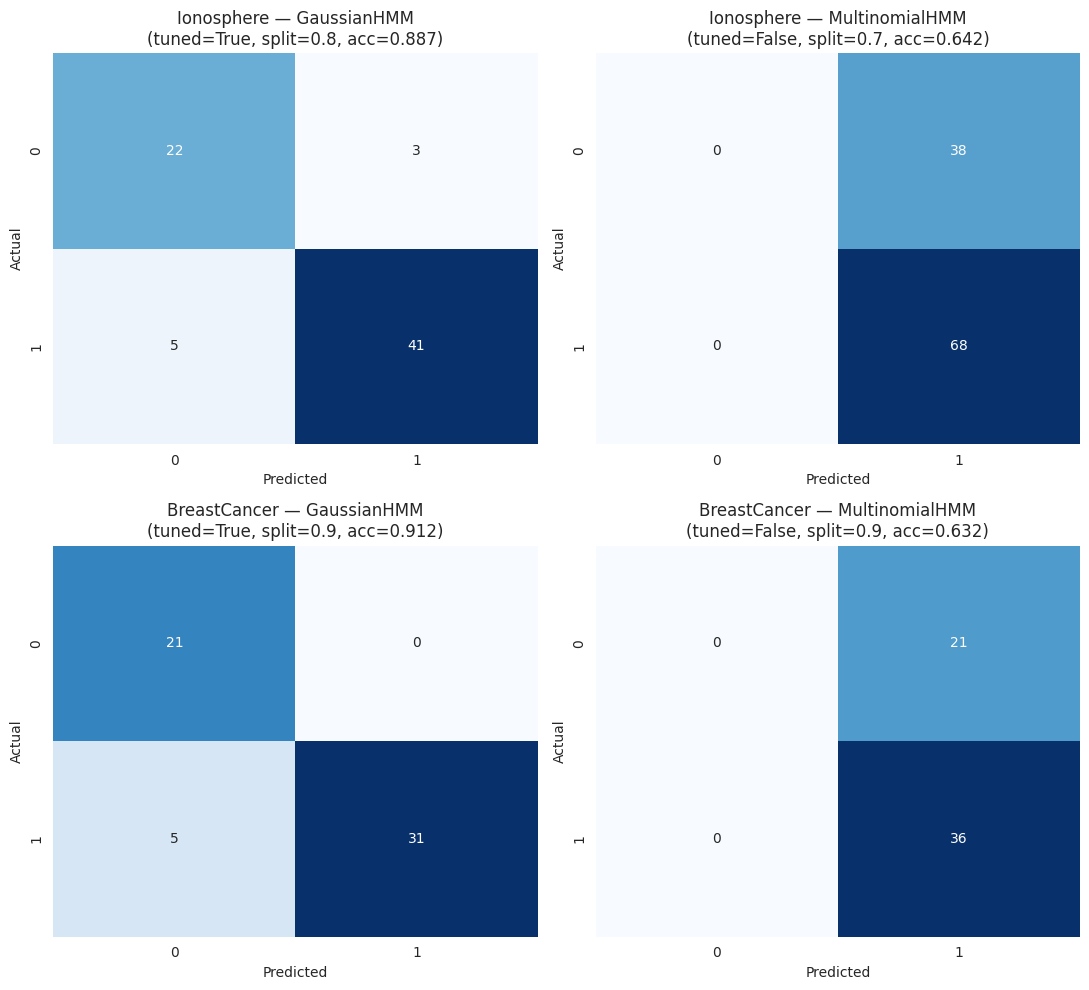

In [ ]:
# Cell 11: Confusion matrix HEATMAPS for the best case of every classifier
fig, axes = plt.subplots(len(datasets), 2, figsize=(11, 5*len(datasets)))
for i, dname in enumerate(datasets):
    for j, clf in enumerate(["GaussianHMM", "MultinomialHMM"]):
        row = best_rows[(best_rows.dataset == dname) & (best_rows.classifier == clf)].iloc[0]
        cm = row["confusion_matrix"]
        ax = axes[i, j] if len(datasets) > 1 else axes[j]
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
        ax.set_title(f"{dname} — {clf}\n(tuned={row['tuned']}, split={row['train_frac']}, acc={row['accuracy']:.3f})")
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("hmm_confusion_matrices_best.png", dpi=150)
plt.show()


**🔹Training ("loss"/log-likelihood) curves for the best models**

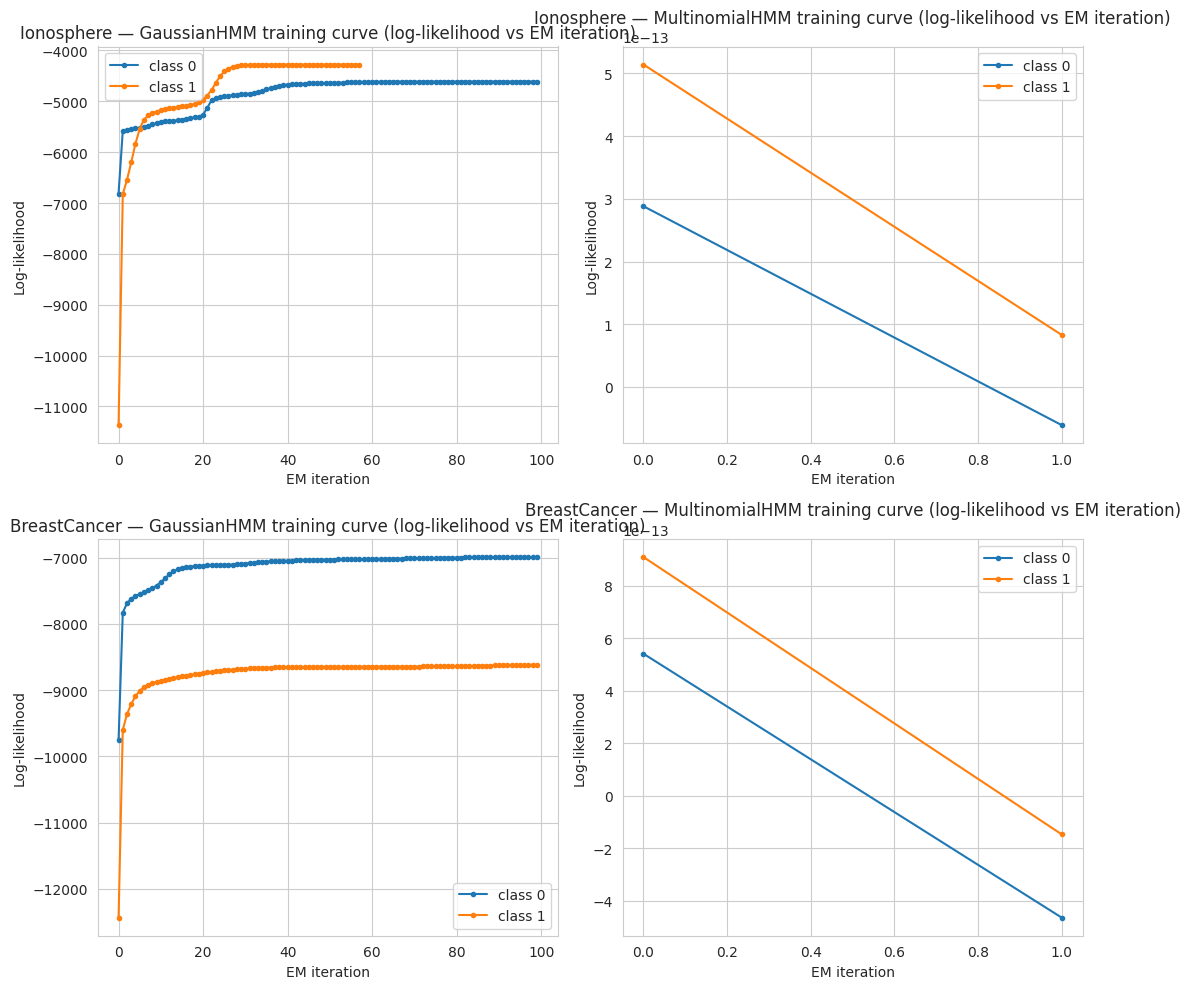

In [ ]:
# Cell 12: Training ("loss"/log-likelihood) curves for the best models
# hmmlearn tracks per-iteration log-likelihood in model.monitor_.history during EM (Baum-Welch).

fig, axes = plt.subplots(len(datasets), 2, figsize=(11, 5*len(datasets)))
for i, dname in enumerate(datasets):
    for j, clf in enumerate(["GaussianHMM", "MultinomialHMM"]):
        row = best_rows[(best_rows.dataset == dname) & (best_rows.classifier == clf)].iloc[0]
        key = (dname, clf, bool(row['tuned']), row['train_frac'])
        models = artifacts[key]["models"]
        ax = axes[i, j] if len(datasets) > 1 else axes[j]
        for c, model in models.items():
            hist = list(model.monitor_.history)
            ax.plot(hist, marker='o', markersize=3, label=f"class {c}")
        ax.set_title(f"{dname} — {clf} training curve (log-likelihood vs EM iteration)")
        ax.set_xlabel("EM iteration"); ax.set_ylabel("Log-likelihood")
        ax.legend()
plt.tight_layout()
plt.savefig("hmm_training_curves_best.png", dpi=150)
plt.show()


**🔹ROC curve + AUC for the best case of every classifier (binary datasets)**

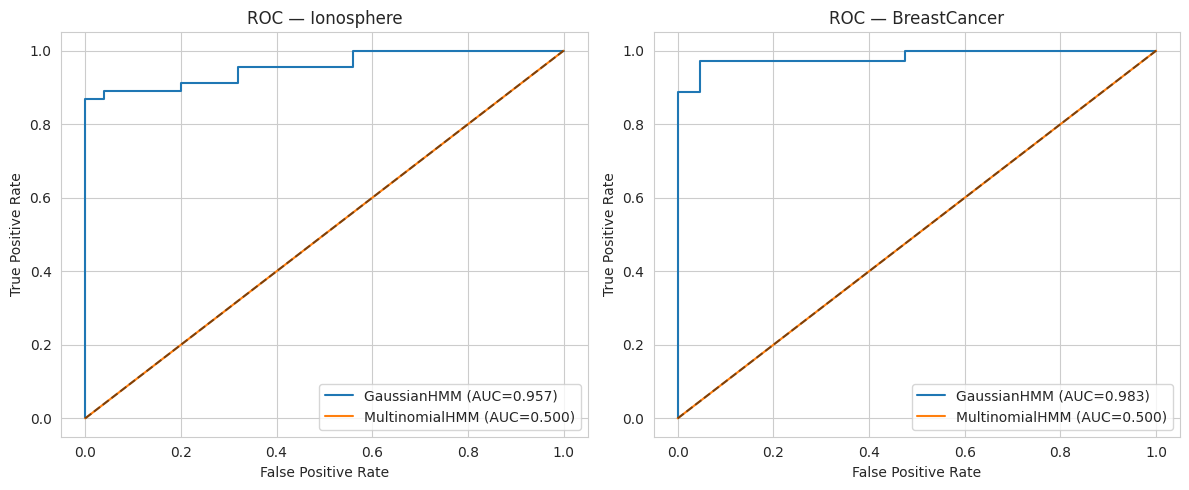

In [ ]:
# Cell 13: ROC curve + AUC for the best case of every classifier (binary datasets)
fig, axes = plt.subplots(1, len(datasets), figsize=(6*len(datasets), 5))
if len(datasets) == 1:
    axes = [axes]

for i, dname in enumerate(datasets):
    ax = axes[i]
    for clf in ["GaussianHMM", "MultinomialHMM"]:
        row = best_rows[(best_rows.dataset == dname) & (best_rows.classifier == clf)].iloc[0]
        key = (dname, clf, bool(row['tuned']), row['train_frac'])
        art = artifacts[key]
        proba = loglik_to_proba(art["L"])
        classes = art["classes"]
        pos_idx = classes.index(1) if 1 in classes else 1
        fpr, tpr, _ = roc_curve(art["y_test"], proba[:, pos_idx])
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, label=f"{clf} (AUC={roc_auc:.3f})")
    ax.plot([0,1],[0,1],'k--', alpha=0.5)
    ax.set_title(f"ROC — {dname}")
    ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
    ax.legend()
plt.tight_layout()
plt.savefig("hmm_roc_curves_best.png", dpi=150)
plt.show()


**🔹Final performance comparison table (pivoted, easy to paste into report)**

In [ ]:
# Cell 14: Final performance comparison table (pivoted, easy to paste into report)
pivot = res_df.pivot_table(index=["dataset","classifier","tuned"],
                            columns="train_frac",
                            values=["accuracy","precision","recall","f1"])
pivot = pivot.round(4)
pivot.to_csv("hmm_comparison_pivot.csv")
pivot


accuracy                              f1  \
train_frac                             0.6     0.7     0.8     0.9     0.6   
dataset      classifier     tuned                                            
BreastCancer GaussianHMM    False   0.8640  0.8655  0.8596  0.8772  0.8848   
                            True    0.8860  0.8947  0.8509  0.9123  0.9110   
             MultinomialHMM False   0.3728  0.6257  0.3684  0.6316  0.0000   
                            True    0.3728  0.6257  0.6316  0.6316  0.0000   
Ionosphere   GaussianHMM    False   0.7730  0.7642  0.8310  0.7500  0.8182   
                            True    0.7730  0.7925  0.8873  0.8333  0.8182   
             MultinomialHMM False   0.6383  0.6415  0.3521  0.3611  0.7792   
                            True    0.3617  0.6415  0.3521  0.3611  0.0000   

                                                          precision          \
train_frac                            0.7     0.8     0.9       0.6     0.7   
dataset      classifier     tuned                                             
BreastCancer GaussianHMM    False  0.8856  0.8788  0.8955    0.9444  0.9468   
                            True   0.9167  0.8702  0.9254    0.8926  0.9083   
             MultinomialHMM False  0.7698  0.0000  0.7742    0.0000  0.6257   
                            True   0.7698  0.7742  0.7742    0.0000  0.6257   
Ionosphere   GaussianHMM    False  0.8120  0.8636  0.7907    0.8372  0.8308   
                            True   0.8553  0.9111  0.8636    0.8372  0.7738   
             MultinomialHMM False  0.7816  0.0000  0.0000    0.6383  0.6415   
                            True   0.7816  0.0000  0.0000    0.0000  0.6415   

                                                   recall                  \
train_frac                            0.8     0.9     0.6     0.7     0.8   
dataset      classifier     tuned                                           
BreastCancer GaussianHMM    False  0.9667  0.9677  0.8322  0.8318  0.8056   
                            True   0.9661  1.0000  0.9301  0.9252  0.7917   
             MultinomialHMM False  0.0000  0.6316  0.0000  1.0000  0.0000   
                            True   0.6316  0.6316  0.0000  1.0000  1.0000   
Ionosphere   GaussianHMM    False  0.9048  0.8500  0.8000  0.7941  0.8261   
                            True   0.9318  0.9048  0.8000  0.9559  0.8913   
             MultinomialHMM False  0.0000  0.0000  1.0000  1.0000  0.0000   
                            True   0.0000  0.0000  0.0000  1.0000  0.0000   

                                           
train_frac                            0.9  
dataset      classifier     tuned          
BreastCancer GaussianHMM    False  0.8333  
                            True   0.8611  
             MultinomialHMM False  1.0000  
                            True   1.0000  
Ionosphere   GaussianHMM    False  0.7391  
                            True   0.8261  
             MultinomialHMM False  0.0000  
                            True   0.0000

# PART 2 & 3: Deep Learning Model Comparison (CNN, VGG-16, AlexNet, GoogLeNet, RNN)

**🔹 Imports & GPU check**

In [ ]:
# Cell 1: Imports & GPU check
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, roc_curve, auc)
from sklearn.preprocessing import label_binarize

print("GPU available:", tf.config.list_physical_devices('GPU'))
np.random.seed(42)
tf.random.set_seed(42)
sns.set_style("whitegrid")


GPU available: []


**🔹Load & preprocess datasets**

In [ ]:
# Cell 2: Load & preprocess datasets
(mnist_xtr, mnist_ytr), (mnist_xte, mnist_yte) = keras.datasets.mnist.load_data()
(cifar_xtr, cifar_ytr), (cifar_xte, cifar_yte) = keras.datasets.cifar10.load_data()

# Combine train+test then we'll do our OWN splits below (assignment asks for
# multiple train/test split ratios, not the canonical fixed split)
mnist_X = np.concatenate([mnist_xtr, mnist_xte], axis=0)
mnist_y = np.concatenate([mnist_ytr, mnist_yte], axis=0).astype(int)
mnist_X = mnist_X.astype("float32") / 255.0
mnist_X = np.expand_dims(mnist_X, -1)          # (N, 28, 28, 1)

cifar_X = np.concatenate([cifar_xtr, cifar_xte], axis=0)
cifar_y = np.concatenate([cifar_ytr, cifar_yte], axis=0).astype(int).ravel()
cifar_X = cifar_X.astype("float32") / 255.0    # (N, 32, 32, 3)

# To keep Colab runtime sane across many (model x dataset x split) combos,
# subsample. Increase these if you have time/GPU budget for higher accuracy.
SUBSET_MNIST = 12000
SUBSET_CIFAR = 12000
rng = np.random.RandomState(42)

idx_m = rng.choice(len(mnist_X), SUBSET_MNIST, replace=False)
mnist_X, mnist_y = mnist_X[idx_m], mnist_y[idx_m]

idx_c = rng.choice(len(cifar_X), SUBSET_CIFAR, replace=False)
cifar_X, cifar_y = cifar_X[idx_c], cifar_y[idx_c]

NUM_CLASSES = 10
DATASETS = {
    "MNIST":   dict(X=mnist_X, y=mnist_y, input_shape=(28,28,1)),
    "CIFAR10": dict(X=cifar_X, y=cifar_y, input_shape=(32,32,3)),
}
for name, d in DATASETS.items():
    print(name, d["X"].shape, d["y"].shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2339s 14us/step
MNIST (12000, 28, 28, 1) (12000,)
CIFAR10 (12000, 32, 32, 3) (12000,)


**🔹Model architectures**

In [ ]:
# Cell 3: Model architectures

def build_cnn(input_shape, num_classes=10):
    m = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(32, 3, activation='relu', padding='same'),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation='relu', padding='same'),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax'),
    ], name="CNN")
    return m

def build_vgg16_small(input_shape, num_classes=10):
    # VGG-style: stacked 3x3 convs + maxpool blocks, scaled down for small images
    inp = layers.Input(shape=input_shape)
    x = inp
    for filters, n_convs in [(32,2), (64,2), (128,3)]:
        for _ in range(n_convs):
            x = layers.Conv2D(filters, 3, activation='relu', padding='same')(x)
        x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(num_classes, activation='softmax')(x)
    return models.Model(inp, x, name="VGG16_small")

def build_alexnet_small(input_shape, num_classes=10):
    inp = layers.Input(shape=input_shape)
    x = layers.Conv2D(64, 3, strides=1, activation='relu', padding='same')(inp)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(128, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(256, 3, activation='relu', padding='same')(x)
    x = layers.Conv2D(256, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(num_classes, activation='softmax')(x)
    return models.Model(inp, x, name="AlexNet_small")

def inception_module(x, f1, f3r, f3, f5r, f5, fpool):
    b1 = layers.Conv2D(f1, 1, padding='same', activation='relu')(x)
    b2 = layers.Conv2D(f3r, 1, padding='same', activation='relu')(x)
    b2 = layers.Conv2D(f3, 3, padding='same', activation='relu')(b2)
    b3 = layers.Conv2D(f5r, 1, padding='same', activation='relu')(x)
    b3 = layers.Conv2D(f5, 5, padding='same', activation='relu')(b3)
    b4 = layers.MaxPooling2D(3, strides=1, padding='same')(x)
    b4 = layers.Conv2D(fpool, 1, padding='same', activation='relu')(b4)
    return layers.concatenate([b1,b2,b3,b4], axis=-1)

def build_googlenet_small(input_shape, num_classes=10):
    inp = layers.Input(shape=input_shape)
    x = layers.Conv2D(64, 3, padding='same', activation='relu')(inp)
    x = layers.MaxPooling2D(2)(x)
    x = inception_module(x, 32, 32, 64, 8, 16, 16)
    x = inception_module(x, 64, 32, 96, 16, 32, 32)
    x = layers.MaxPooling2D(2)(x)
    x = inception_module(x, 96, 48, 128, 16, 32, 32)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(num_classes, activation='softmax')(x)
    return models.Model(inp, x, name="GoogLeNet_small")

def build_rnn(input_shape, num_classes=10):
    # Treat each image as a sequence of rows: shape (H, W*C)
    h, w, c = input_shape
    inp = layers.Input(shape=input_shape)
    x = layers.Reshape((h, w*c))(inp)
    x = layers.LSTM(128, return_sequences=True)(x)
    x = layers.LSTM(64)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(num_classes, activation='softmax')(x)
    return models.Model(inp, x, name="RNN_LSTM")

MODEL_BUILDERS = {
    "CNN": build_cnn,
    "VGG16": build_vgg16_small,
    "AlexNet": build_alexnet_small,
    "GoogLeNet": build_googlenet_small,
    "RNN": build_rnn,
}


**🔹Train/evaluate helper**

In [ ]:
# Cell 4: Train/evaluate helper

EPOCHS = 12
BATCH_SIZE = 128
SPLITS = [0.6, 0.7, 0.8]   # fraction of data used for TRAINING

def train_and_eval(model_name, dataset_name, train_frac):
    d = DATASETS[dataset_name]
    X, y, input_shape = d["X"], d["y"], d["input_shape"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, train_size=train_frac, stratify=y, random_state=42)

    y_train_oh = keras.utils.to_categorical(y_train, NUM_CLASSES)
    y_test_oh = keras.utils.to_categorical(y_test, NUM_CLASSES)

    model = MODEL_BUILDERS[model_name](input_shape, NUM_CLASSES)
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

    es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
    history = model.fit(X_train, y_train_oh, validation_split=0.15,
                         epochs=EPOCHS, batch_size=BATCH_SIZE,
                         callbacks=[es], verbose=0)

    y_proba = model.predict(X_test, verbose=0)
    y_pred = np.argmax(y_proba, axis=1)

    metrics = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "f1": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "confusion_matrix": confusion_matrix(y_test, y_pred),
    }
    artifact = dict(history=history.history, y_test=y_test, y_proba=y_proba, model_name=model_name)
    return metrics, artifact


**🔹Mount Drive & load checkpoint (survives disconnects/crashes)**

In [ ]:
# Cell 5a: Mount Drive & load checkpoint (survives disconnects/crashes)
# This trains many models x datasets x splits, which can take a long time.
# Colab sessions can disconnect (idle timeout, ~12hr cap, etc). To avoid
# losing all progress when that happens, results are checkpointed to Google
# Drive after EVERY (dataset, model, split) combo. If this cell is re-run
# after a disconnect, it reloads whatever was already completed, and the
# training loop below will automatically skip combos already finished.

from google.colab import drive
drive.mount('/content/drive')

import pickle, os
CKPT_PATH = "/content/drive/MyDrive/dl_assignment_checkpoint.pkl"

if os.path.exists(CKPT_PATH):
    with open(CKPT_PATH, "rb") as f:
        results, artifacts = pickle.load(f)
    done = {(r["dataset"], r["model"], r["train_frac"]) for r in results}
    print(f"Found existing checkpoint — {len(done)} combo(s) already completed, will be skipped.")
else:
    results, artifacts = [], {}
    done = set()
    print("No checkpoint found — starting fresh.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
No checkpoint found — starting fresh.


**🔹Main experiment loop — every model x every dataset x every split**

In [ ]:
# Cell 5b: Main experiment loop — every model x every dataset x every split
# Safe to interrupt/disconnect at any point: just re-run Cell 5a then this
# cell again, and it will resume from the next un-finished combo instead of
# starting over.

for dataset_name in DATASETS:
    for model_name in MODEL_BUILDERS:
        for train_frac in SPLITS:
            key = (dataset_name, model_name, train_frac)
            if key in done:
                print(f"Skipping (already done): {model_name} on {dataset_name} (train_frac={train_frac})")
                continue

            print(f"Training {model_name} on {dataset_name} (train_frac={train_frac}) ...")
            metrics, art = train_and_eval(model_name, dataset_name, train_frac)
            results.append(dict(dataset=dataset_name, model=model_name, train_frac=train_frac,
                                 **{k:v for k,v in metrics.items() if k != "confusion_matrix"},
                                 confusion_matrix=metrics["confusion_matrix"]))
            artifacts[key] = art
            done.add(key)

            # Checkpoint to Drive after EVERY combo so nothing is lost on disconnect
            with open(CKPT_PATH, "wb") as f:
                pickle.dump((results, artifacts), f)

print("\nAll experiments complete.")


Training CNN on MNIST (train_frac=0.6) ...
Training CNN on MNIST (train_frac=0.7) ...
Training CNN on MNIST (train_frac=0.8) ...
Training VGG16 on MNIST (train_frac=0.6) ...
Training VGG16 on MNIST (train_frac=0.7) ...
Training VGG16 on MNIST (train_frac=0.8) ...
Training AlexNet on MNIST (train_frac=0.6) ...
Training AlexNet on MNIST (train_frac=0.7) ...
Training AlexNet on MNIST (train_frac=0.8) ...
Training GoogLeNet on MNIST (train_frac=0.6) ...
Training GoogLeNet on MNIST (train_frac=0.7) ...
Training GoogLeNet on MNIST (train_frac=0.8) ...
Training RNN on MNIST (train_frac=0.6) ...
Training RNN on MNIST (train_frac=0.7) ...
Training RNN on MNIST (train_frac=0.8) ...
Training CNN on CIFAR10 (train_frac=0.6) ...
Training CNN on CIFAR10 (train_frac=0.7) ...
Training CNN on CIFAR10 (train_frac=0.8) ...
Training VGG16 on CIFAR10 (train_frac=0.6) ...
Training VGG16 on CIFAR10 (train_frac=0.7) ...
Training VGG16 on CIFAR10 (train_frac=0.8) ...
Training AlexNet on CIFAR10 (train_frac=0.6

**🔹Results table**

In [ ]:
# Cell 6: Results table
res_df = pd.DataFrame(results)
display_df = res_df.drop(columns=["confusion_matrix"]).copy()
display_df[["accuracy","precision","recall","f1"]] = display_df[["accuracy","precision","recall","f1"]].round(4)
display_df = display_df.sort_values(["dataset","model","train_frac"])
display_df.to_csv("dl_results_full.csv", index=False)
display_df


,dataset,model,train_frac,accuracy,precision,recall,f1
21,CIFAR10,AlexNet,0.6,0.5869,0.5833,0.5864,0.5815
22,CIFAR10,AlexNet,0.7,0.5983,0.6079,0.5971,0.5973
23,CIFAR10,AlexNet,0.8,0.6204,0.6327,0.6201,0.6208
15,CIFAR10,CNN,0.6,0.5350,0.5403,0.5348,0.5351
16,CIFAR10,CNN,0.7,0.5794,0.5878,0.5796,0.5759
17,CIFAR10,CNN,0.8,0.5571,0.5630,0.5580,0.5498
24,CIFAR10,GoogLeNet,0.6,0.4585,0.4755,0.4580,0.4480
25,CIFAR10,GoogLeNet,0.7,0.5075,0.4987,0.5065,0.4917
26,CIFAR10,GoogLeNet,0.8,0.5096,0.5335,0.5109,0.5030
27,CIFAR10,RNN,0.6,0.4081,0.4216,0.4077,0.4059


**🔹Best case per (dataset, model)**

In [ ]:
# Cell 7: Best case per (dataset, model)
best_rows = (res_df.sort_values("accuracy", ascending=False)
                    .groupby(["dataset","model"], as_index=False).first())
best_rows_display = best_rows.drop(columns=["confusion_matrix"])
best_rows_display


,dataset,model,train_frac,accuracy,precision,recall,f1
0,CIFAR10,AlexNet,0.8,0.620417,0.632700,0.620128,0.620797
1,CIFAR10,CNN,0.7,0.579444,0.587849,0.579563,0.575945
2,CIFAR10,GoogLeNet,0.8,0.509583,0.533550,0.510935,0.503000
3,CIFAR10,RNN,0.8,0.455000,0.456875,0.454314,0.447097
4,CIFAR10,VGG16,0.7,0.591944,0.597582,0.591688,0.587446
5,MNIST,AlexNet,0.8,0.979167,0.979533,0.979084,0.979139
6,MNIST,CNN,0.8,0.974583,0.975069,0.974248,0.974491
7,MNIST,GoogLeNet,0.7,0.968333,0.968818,0.968071,0.968286
8,MNIST,RNN,0.8,0.945417,0.946016,0.944916,0.944982
9,MNIST,VGG16,0.7,0.979722,0.979618,0.979742,0.979558


**🔹Confusion matrix HEATMAPS for the best case of every model**

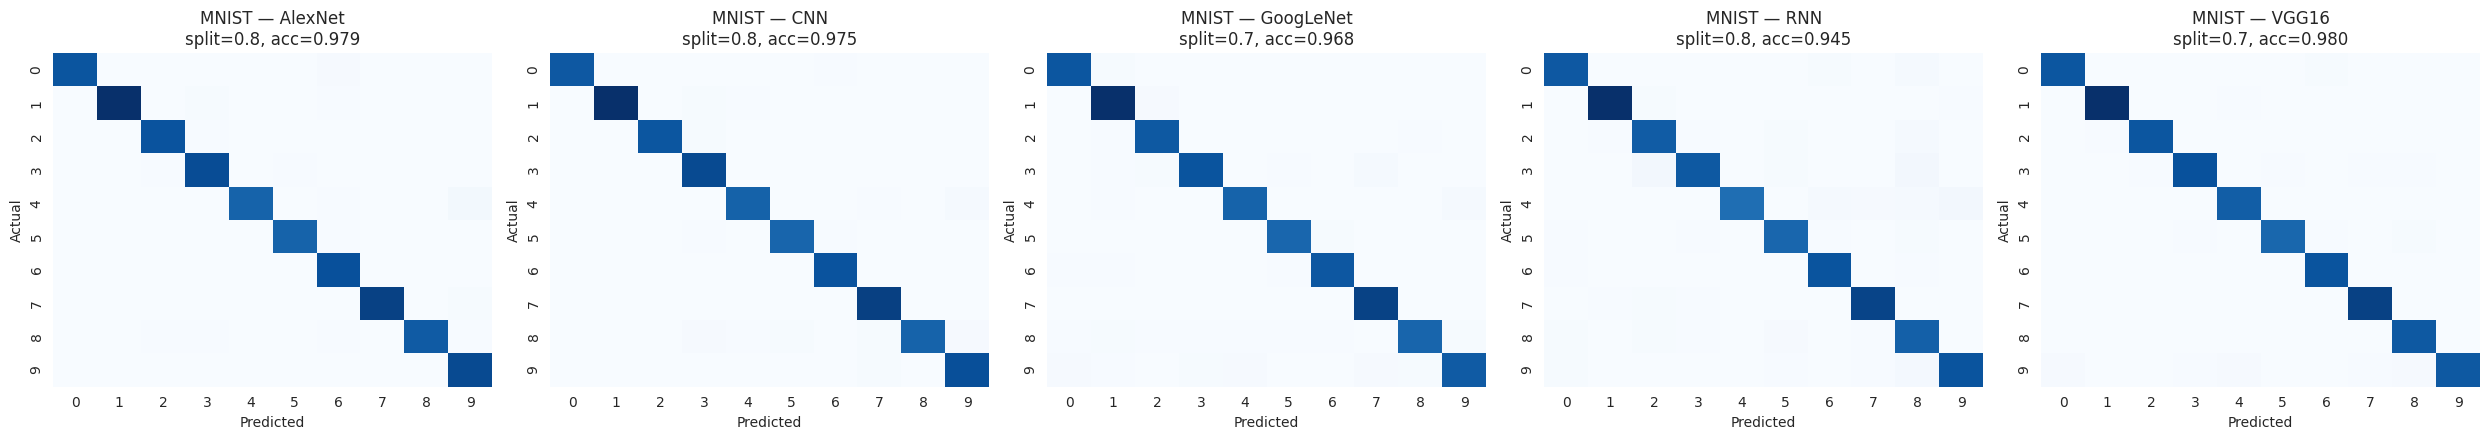

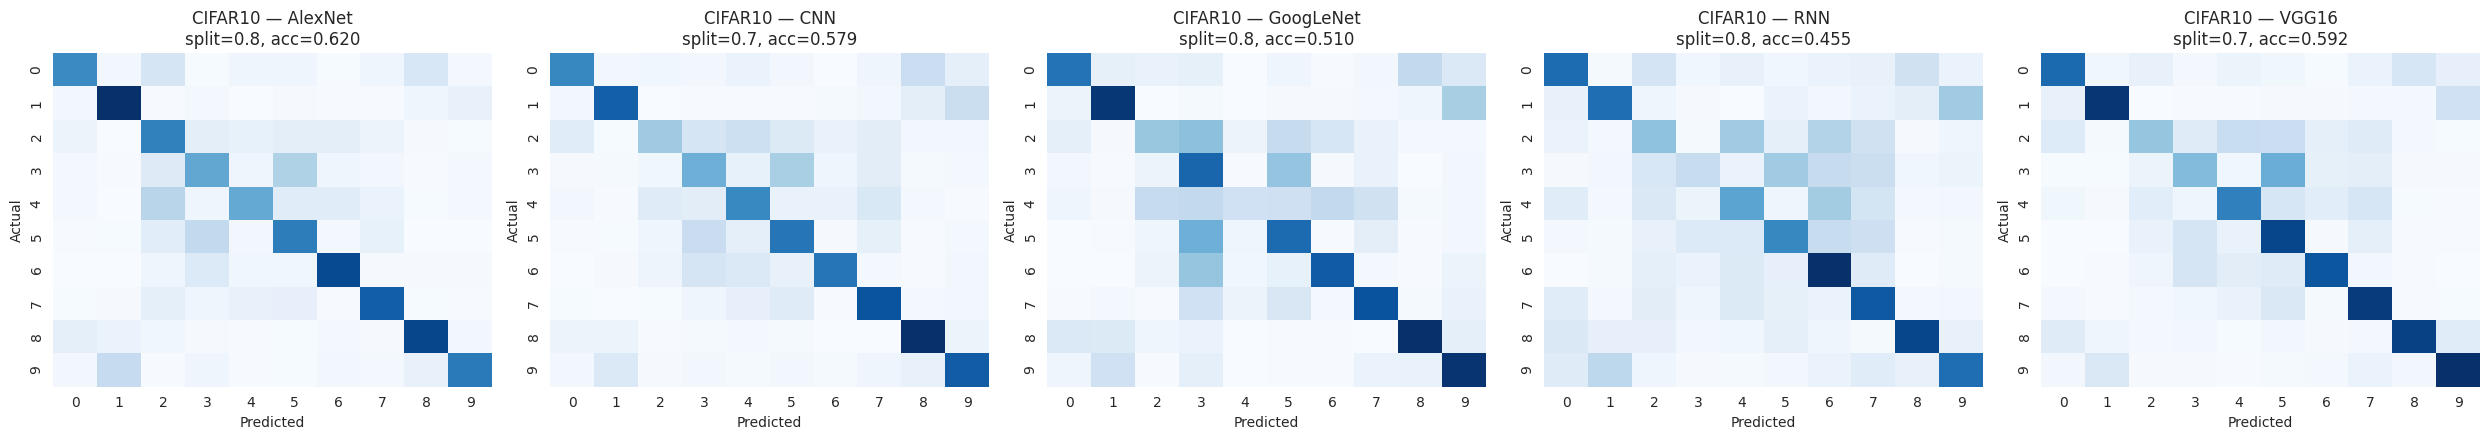

In [ ]:
# Cell 8: Confusion matrix HEATMAPS for the best case of every model
for dataset_name in DATASETS:
    sub = best_rows[best_rows.dataset == dataset_name]
    n = len(sub)
    fig, axes = plt.subplots(1, n, figsize=(5*n, 4.5))
    if n == 1: axes = [axes]
    for ax, (_, row) in zip(axes, sub.iterrows()):
        cm = row["confusion_matrix"]
        sns.heatmap(cm, annot=False, cmap="Blues", ax=ax, cbar=False)
        ax.set_title(f"{dataset_name} — {row['model']}\nsplit={row['train_frac']}, acc={row['accuracy']:.3f}")
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    plt.tight_layout()
    plt.savefig(f"dl_confusion_matrices_best_{dataset_name}.png", dpi=150)
    plt.show()


**🔹Training & validation loss/accuracy curves for every model (best split shown)**

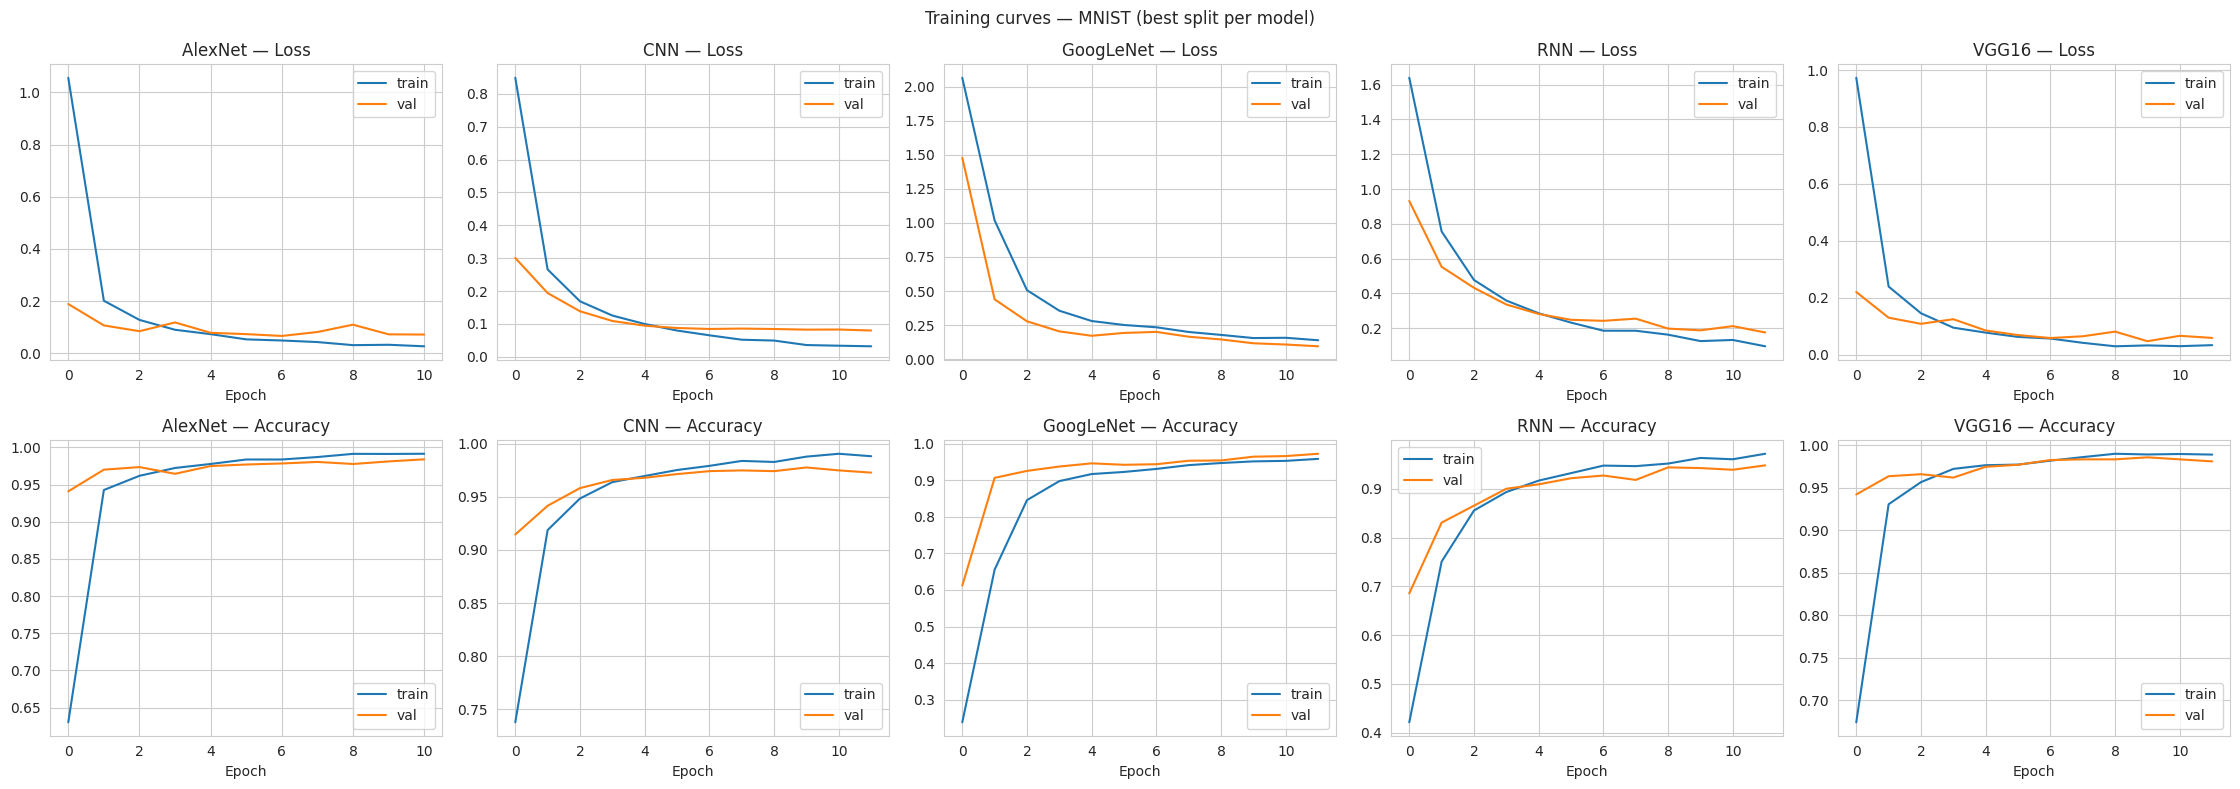

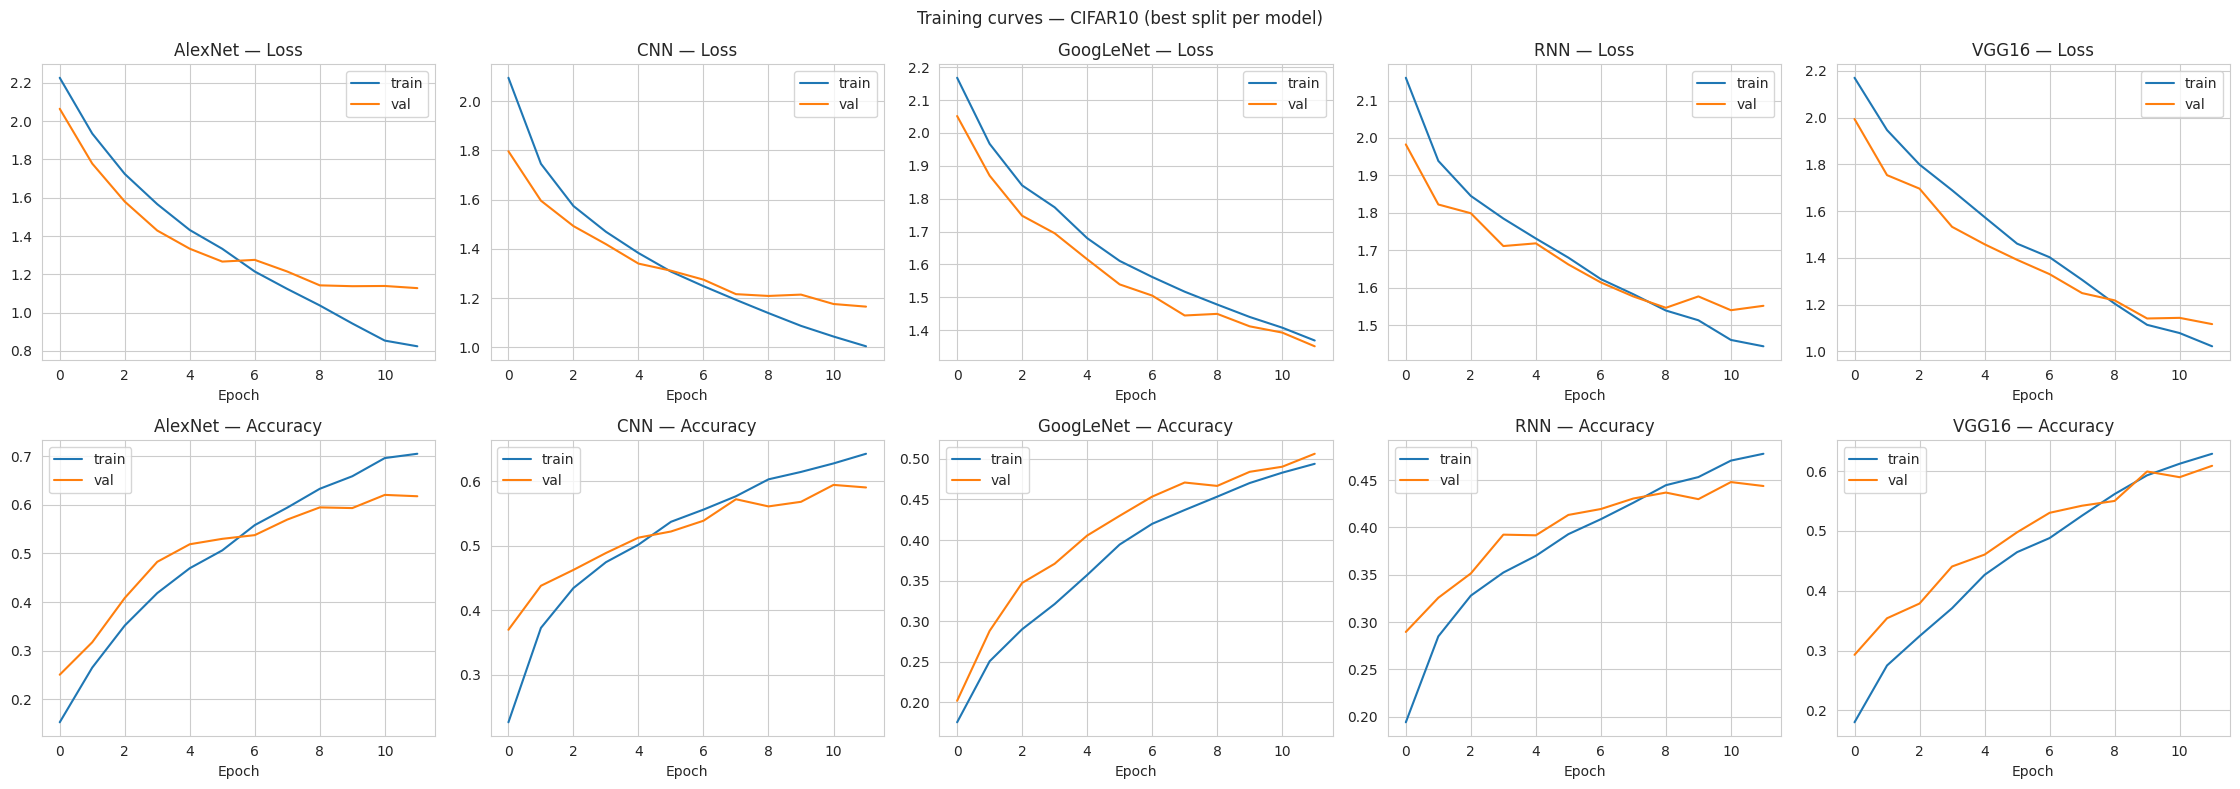

In [ ]:
# Cell 9: Training & validation loss/accuracy curves for every model (best split shown)
for dataset_name in DATASETS:
    sub = best_rows[best_rows.dataset == dataset_name]
    n = len(sub)
    fig, axes = plt.subplots(2, n, figsize=(4.5*n, 8))
    for col, (_, row) in enumerate(sub.iterrows()):
        art = artifacts[(dataset_name, row['model'], row['train_frac'])]
        h = art["history"]
        ax_loss = axes[0, col] if n > 1 else axes[0]
        ax_acc  = axes[1, col] if n > 1 else axes[1]
        ax_loss.plot(h['loss'], label='train'); ax_loss.plot(h['val_loss'], label='val')
        ax_loss.set_title(f"{row['model']} — Loss"); ax_loss.set_xlabel("Epoch"); ax_loss.legend()
        ax_acc.plot(h['accuracy'], label='train'); ax_acc.plot(h['val_accuracy'], label='val')
        ax_acc.set_title(f"{row['model']} — Accuracy"); ax_acc.set_xlabel("Epoch"); ax_acc.legend()
    plt.suptitle(f"Training curves — {dataset_name} (best split per model)")
    plt.tight_layout()
    plt.savefig(f"dl_training_curves_{dataset_name}.png", dpi=150)
    plt.show()


**🔹Multi-class ROC + AUC (macro one-vs-rest) for the best case of every model**

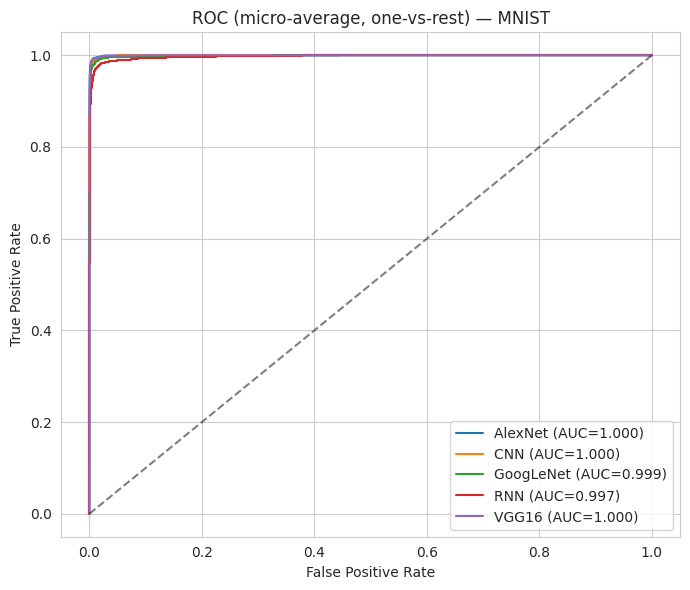

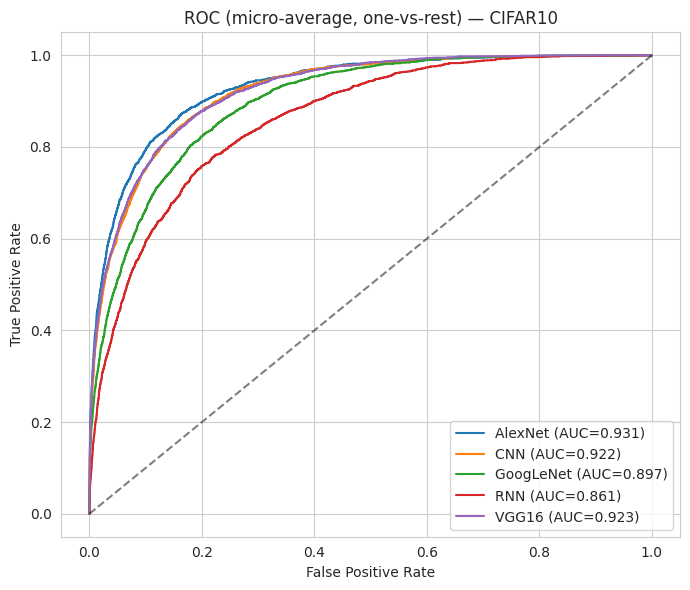

In [ ]:
# Cell 10: Multi-class ROC + AUC (macro one-vs-rest) for the best case of every model
for dataset_name in DATASETS:
    sub = best_rows[best_rows.dataset == dataset_name]
    fig, ax = plt.subplots(figsize=(7,6))
    for _, row in sub.iterrows():
        art = artifacts[(dataset_name, row['model'], row['train_frac'])]
        y_test, y_proba = art["y_test"], art["y_proba"]
        y_test_bin = label_binarize(y_test, classes=list(range(NUM_CLASSES)))
        fpr, tpr, _ = roc_curve(y_test_bin.ravel(), y_proba.ravel())  # micro-average
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, label=f"{row['model']} (AUC={roc_auc:.3f})")
    ax.plot([0,1],[0,1],'k--', alpha=0.5)
    ax.set_title(f"ROC (micro-average, one-vs-rest) — {dataset_name}")
    ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
    ax.legend()
    plt.tight_layout()
    plt.savefig(f"dl_roc_curves_{dataset_name}.png", dpi=150)
    plt.show()


**🔹Final comparison table (pivoted, easy to paste into the report)**

In [ ]:
# Cell 11: Final comparison table (pivoted, easy to paste into the report)
pivot = res_df.pivot_table(index=["dataset","model"], columns="train_frac",
                            values=["accuracy","precision","recall","f1"])
pivot = pivot.round(4)
pivot.to_csv("dl_comparison_pivot.csv")
pivot


accuracy                      f1                 precision  \
train_frac             0.6     0.7     0.8     0.6     0.7     0.8       0.6   
dataset model                                                                  
CIFAR10 AlexNet     0.5869  0.5983  0.6204  0.5815  0.5973  0.6208    0.5833   
        CNN         0.5350  0.5794  0.5571  0.5351  0.5759  0.5498    0.5403   
        GoogLeNet   0.4585  0.5075  0.5096  0.4480  0.4917  0.5030    0.4755   
        RNN         0.4081  0.4386  0.4550  0.4059  0.4233  0.4471    0.4216   
        VGG16       0.5408  0.5919  0.5796  0.5436  0.5874  0.5772    0.5623   
MNIST   AlexNet     0.9783  0.9789  0.9792  0.9782  0.9788  0.9791    0.9781   
        CNN         0.9706  0.9731  0.9746  0.9703  0.9729  0.9745    0.9705   
        GoogLeNet   0.9602  0.9683  0.9667  0.9599  0.9683  0.9666    0.9604   
        RNN         0.9333  0.9425  0.9454  0.9331  0.9420  0.9450    0.9343   
        VGG16       0.9704  0.9797  0.9792  0.9701  0.9796  0.9791    0.9702   

                                   recall                  
train_frac            0.7     0.8     0.6     0.7     0.8  
dataset model                                              
CIFAR10 AlexNet    0.6079  0.6327  0.5864  0.5971  0.6201  
        CNN        0.5878  0.5630  0.5348  0.5796  0.5580  
        GoogLeNet  0.4987  0.5335  0.4580  0.5065  0.5109  
        RNN        0.4357  0.4569  0.4077  0.4388  0.4543  
        VGG16      0.5976  0.5905  0.5406  0.5917  0.5795  
MNIST   AlexNet    0.9788  0.9795  0.9784  0.9789  0.9791  
        CNN        0.9731  0.9751  0.9706  0.9729  0.9742  
        GoogLeNet  0.9688  0.9671  0.9597  0.9681  0.9666  
        RNN        0.9429  0.9460  0.9330  0.9418  0.9449  
        VGG16      0.9796  0.9792  0.9706  0.9797  0.9791